---
title: "Hilbert Space and Dirac Notation"
short_title: "Q-M3 Hilbert Space & Dirac Notation"
numbering:
  heading_2: true
  equation: true
---

# Hilbert Space and Dirac Notation

:::{tip} Where this sits in the plan
Math for the **formalism** (quantum topic 4) and everything after it. Mechanics M6 covers matrices and eigenvalues in real vector spaces; this notebook extends them to complex vectors and to functions.

| Item | Stewart | Boas | Zill | Arfken |
|---|---|---|---|---|
| Matrices and determinants | – | 3 | 8 | 2 |
| Vector spaces and Hilbert space | – | 3 | – | 5, 6 |
| Eigenvalues and diagonalization | – | 3 | 8 | 6 |

Chapter numbers are approximate, as in the workbook.
:::

Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq
from scipy import special

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
hbar = 1.054572e-34    # J s
m_e = 9.10938e-31      # kg
eV = 1.602177e-19      # J
a0 = 5.29177e-11       # m (Bohr radius)
np.seterr(over="ignore", divide="ignore", invalid="ignore")   # plots hit inf at the edges; harmless here

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## Complex Vector Spaces

A vector space over the complex numbers has the familiar rules (add vectors, multiply by scalars) with complex scalars. The new ingredient is the **inner product** $\langle\alpha|\beta\rangle$, a complex number with

$$
\langle\beta|\alpha\rangle = \langle\alpha|\beta\rangle^*,\qquad
\langle\alpha|\alpha\rangle\ge0\ (= 0\text{ only for the zero vector}),\qquad
\langle\alpha|(c\beta + d\gamma)\rangle = c\langle\alpha|\beta\rangle + d\langle\alpha|\gamma\rangle .
$$ (eq-inner-product-rules)

It is linear in the second slot and *conjugate*-linear in the first. For column vectors, $\langle\alpha|\beta\rangle = \sum_i\alpha_i^*\beta_i = \alpha^\dagger\beta$, where $\dagger$ (the **Hermitian conjugate**) is transpose plus complex conjugate. The conjugate is what keeps $\langle\alpha|\alpha\rangle = \sum|\alpha_i|^2$ real and positive.

**Functions are vectors too.** Square-integrable functions on an interval form a vector space with

$$
\langle f|g\rangle = \int f(x)^*g(x)\,dx .
$$ (eq-function-inner-product)

The space of functions with $\langle f|f\rangle < \infty$ is **Hilbert space** ($L^2$). Wave functions live there, which is why they must be normalizable.

**Schwarz inequality.** $|\langle f|g\rangle|^2\le\langle f|f\rangle\langle g|g\rangle$. It is the complex version of $|\vec a\cdot\vec b|\le|\vec a||\vec b|$, and it is the whole engine of the uncertainty principle (quantum topic 4).

## Dirac Notation

Write a vector as a **ket** $|\alpha\rangle$ and its dual (the linear map "take the inner product with $\alpha$") as a **bra** $\langle\alpha|$. For columns, the bra is the conjugate row $\alpha^\dagger$. Then:

- $\langle\alpha|\beta\rangle$ is a number (bra times ket);
- $|\beta\rangle\langle\alpha|$ is an operator (ket times bra), which takes $|\gamma\rangle$ to $|\beta\rangle\langle\alpha|\gamma\rangle$;
- an orthonormal basis $\{|e_n\rangle\}$ satisfies $\langle e_m|e_n\rangle = \delta_{mn}$, and any vector expands as $|\alpha\rangle = \sum_n|e_n\rangle\langle e_n|\alpha\rangle$.

That last line says the identity operator is

$$
\hat 1 = \sum_n|e_n\rangle\langle e_n| ,
$$ (eq-completeness)

the **completeness relation**. Inserting it is the single most useful trick in the subject: it converts any abstract expression into components in a chosen basis. Each term $\hat P_n = |e_n\rangle\langle e_n|$ is a **projection operator** onto one basis direction.

In [2]:
# A 3-dimensional example: build projectors from an orthonormal basis and check they sum to the identity
e1 = sp.Matrix([1, sp.I, 0]) / sp.sqrt(2)
e2 = sp.Matrix([1, -sp.I, 0]) / sp.sqrt(2)
e3 = sp.Matrix([0, 0, 1])
basis = [e1, e2, e3]
gram = sp.Matrix(3, 3, lambda i, j: (basis[i].H * basis[j])[0])
P_sum = sum((e * e.H for e in basis), sp.zeros(3))
display(Math(r"\langle e_i|e_j\rangle = " + sp.latex(gram) + r",\qquad \sum_n |e_n\rangle\langle e_n| = " + sp.latex(sp.simplify(P_sum))))

<IPython.core.display.Math object>

## Operators and Their Matrices

A linear operator $\hat Q$ maps kets to kets. In a basis it is a matrix, $Q_{mn} = \langle e_m|\hat Q|e_n\rangle$, and every operator equation becomes a matrix equation. Two definitions matter most.

:::{prf:definition} Hermitian conjugate and Hermitian operators
:label: def-hermitian-operator

The **Hermitian conjugate** $\hat Q^\dagger$ is defined by $\langle\alpha|\hat Q\beta\rangle = \langle\hat Q^\dagger\alpha|\beta\rangle$ for all $\alpha$, $\beta$; its matrix is the conjugate transpose of $\hat Q$'s. $\hat Q$ is **Hermitian** if $\hat Q^\dagger = \hat Q$.
:::

:::{prf:theorem} Spectral theorem for Hermitian operators
:label: thm-hermitian-spectrum

For a Hermitian operator:

1. every eigenvalue is real;
2. eigenvectors with different eigenvalues are orthogonal;
3. (in finite dimensions, and for the operators of physics in general) the eigenvectors form a complete basis.
:::

:::{prf:proof} Proof of 1 and 2
:class: dropdown

Let $\hat Q|q\rangle = q|q\rangle$ and $\hat Q|q'\rangle = q'|q'\rangle$. Then

$$
q'\langle q|q'\rangle = \langle q|\hat Qq'\rangle = \langle\hat Qq|q'\rangle = q^*\langle q|q'\rangle .
$$

With $q' = q$ (and $\langle q|q\rangle\ne0$): $q = q^*$, real. With $q'\ne q$ (both real now): $(q' - q)\langle q|q'\rangle = 0$, so $\langle q|q'\rangle = 0$.
:::

This is why observables are Hermitian: measured values must be real, and the outcomes must form a basis you can expand any state in. **Unitary** operators ($\hat U^\dagger\hat U = \hat 1$) are the other important class: they preserve inner products, so they describe time evolution and changes of basis.

**Commutators.** $[\hat A, \hat B] = \hat A\hat B - \hat B\hat A$. Matrices generally do not commute, and in quantum mechanics that is physics, not a nuisance: $[\hat x, \hat p] = i\hbar$.

In [3]:
# Hermitian vs not: eigenvalues and orthogonality, numerically
rng = np.random.default_rng(3)
A = rng.normal(size=(4, 4)) + 1j * rng.normal(size=(4, 4))
H = (A + A.conj().T) / 2                     # Hermitian part
w, V = np.linalg.eigh(H)
display(Math(r"\text{eigenvalues of } H = " + sp.latex(sp.Matrix(np.round(w, 4)).T)))
display(Math(r"\max|V^\dagger V - 1| = " + f"{np.abs(V.conj().T @ V - np.eye(4)).max():.1e}"))
wA = np.linalg.eigvals(A)
display(Math(r"\text{eigenvalues of } A\ (\text{not Hermitian}) = " + sp.latex(sp.Matrix(np.round(wA, 3)).T)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Operators on Functions

On functions, operators include multiplication ($\hat x f = xf$) and differentiation. Is $\hat D = d/dx$ Hermitian? Integrate by parts, with boundary terms vanishing for normalizable functions:

$$
\langle f|\hat Dg\rangle = \int f^*g'\,dx = -\int(f')^*g\,dx = -\langle\hat Df|g\rangle .
$$

So $\hat D^\dagger = -\hat D$ (it is *anti*-Hermitian), and $\hat p = -i\hbar\hat D$ is Hermitian: the factor $-i$ fixes the sign. Similarly $d^2/dx^2$ is Hermitian, so the kinetic energy is.

**Eigenfunctions with a continuous spectrum.** $\hat p$'s eigenfunctions $f_p(x) = e^{ipx/\hbar}/\sqrt{2\pi\hbar}$ are not normalizable, and their eigenvalues fill the real line. They are orthonormal in the delta-function sense,

$$
\langle f_p|f_{p'}\rangle = \delta(p - p') ,
$$ (eq-delta-normalization)

and complete, with the sum in {eq}`eq-completeness` replaced by an integral: $\int|f_p\rangle\langle f_p|\,dp = \hat 1$. Expanding a state in them is exactly the Fourier transform of Q-M1, with $\Phi(p) = \langle f_p|\Psi\rangle$.

## Solving Eigenvalue Problems in a Basis

Any eigenvalue problem $\hat H|\psi\rangle = E|\psi\rangle$ becomes a matrix problem once you pick a basis: $\sum_nH_{mn}c_n = Ec_m$. Truncating to the first $N$ basis functions gives a finite matrix whose eigenvalues approximate the true ones (from above, for the lowest; quantum topic 9 explains why). This is how most real quantum calculations are done.

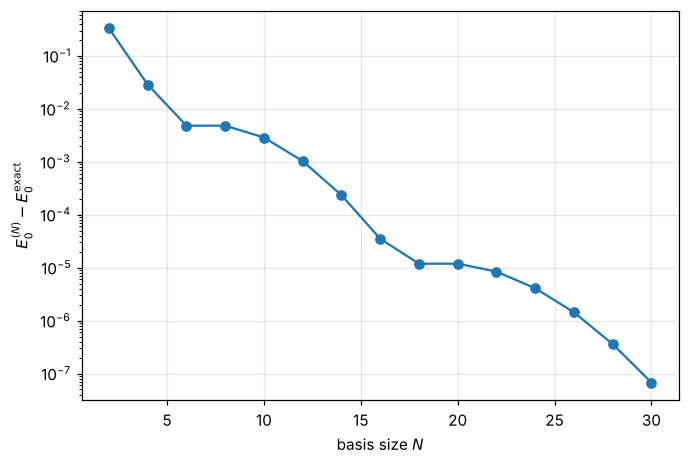

<IPython.core.display.Math object>

In [4]:
#| label: fig-basis-convergence
#| caption: "Ground-state energy of the quartic oscillator H = p²/2 + x⁴ (ħ = m = 1) from diagonalizing H in the first N harmonic-oscillator states. The estimate falls toward the exact value 0.667986 from above and converges rapidly; with N = 30 it is right to about seven digits."
def ho_matrices(N):
    n = np.arange(N)
    a = np.diag(np.sqrt(n[1:]), 1)                  # lowering operator in the HO basis
    X = (a + a.T) / np.sqrt(2)
    P = 1j * (a.T - a) / np.sqrt(2)
    return X, P
Ns = np.arange(2, 32, 2)
E0 = []
for N in Ns:
    X, P = ho_matrices(N + 8)                     # build bigger, then truncate H (avoids edge errors in X^4)
    Hfull = (P @ P).real / 2 + np.linalg.matrix_power(X, 4)
    E0.append(np.linalg.eigvalsh(Hfull[:N, :N])[0])
fig, ax = plt.subplots()
ax.semilogy(Ns, np.array(E0) - 0.667986259, "o-")
ax.set_xlabel("basis size $N$"); ax.set_ylabel("$E_0^{(N)} - E_0^{\\rm exact}$"); plt.show()
display(Math(rf"E_0^{{(30)}} = {E0[-1]:.7f}"))

### Exercises

1. Show that $\langle\alpha|\beta\rangle$ for column vectors is $\alpha^\dagger\beta$, and that $(\hat A\hat B)^\dagger = \hat B^\dagger\hat A^\dagger$ for matrices.
2. Find the eigenvalues and normalized eigenvectors of $\begin{pmatrix}0 & -i\\ i & 0\end{pmatrix}$, and check the spectral theorem.
3. Show that $\hat x$ (multiplication by $x$) is Hermitian, and that $\hat x\hat p$ is not. What combination of $\hat x\hat p$ and $\hat p\hat x$ is?
4. Compute $[\hat x, \hat p]$ by acting on a test function $f(x)$.
5. Show that eigenvalues of a unitary operator have modulus 1.

:::{dropdown} Hints
1. Write out components; for the product rule, use $(AB)^T = B^TA^T$.
2. Characteristic equation $\lambda^2 - 1 = 0$.
3. $(\hat x\hat p)^\dagger = \hat p^\dagger\hat x^\dagger$.
4. $\hat x\hat pf = -i\hbar xf'$; $\hat p\hat xf = -i\hbar(xf)'$.
5. $\langle u|u\rangle = \langle\hat Uu|\hat Uu\rangle$.
:::

:::{dropdown} Answers
1. Direct from the definitions.
2. $\lambda = \pm1$, with $\tfrac{1}{\sqrt2}(1, \pm i)^T$; real eigenvalues, orthogonal eigenvectors.
3. $\int f^*xg = \int(xf)^*g$ since $x$ is real. $(\hat x\hat p)^\dagger = \hat p\hat x\ne\hat x\hat p$. The symmetric combination $\tfrac12(\hat x\hat p + \hat p\hat x)$ is Hermitian.
4. $[\hat x, \hat p]f = -i\hbar xf' + i\hbar(f + xf') = i\hbar f$, so $[\hat x, \hat p] = i\hbar$.
5. If $\hat U|u\rangle = \lambda|u\rangle$, then $\langle u|u\rangle = |\lambda|^2\langle u|u\rangle$, so $|\lambda| = 1$.
:::

## Summary

- Complex inner products are conjugate-linear in the first slot; functions with finite $\int|f|^2$ form Hilbert space.
- Kets are vectors, bras are their conjugate duals; $\sum|e_n\rangle\langle e_n| = \hat 1$ converts anything to components.
- Hermitian operators ($\hat Q^\dagger = \hat Q$) have real eigenvalues and complete orthogonal eigenvectors: they represent observables. $\hat p = -i\hbar\,d/dx$ is Hermitian because of the $-i$.
- Continuous spectra use delta normalization; momentum eigenfunctions give the Fourier transform.
- In a truncated basis, $\hat H$ is a matrix and the eigenvalue problem is numerical linear algebra.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.